<a href="https://colab.research.google.com/github/AmarSai01/nvidia-gpu-ml-jax-labs/blob/main/02_RAPIDS_cuML_Taxi_Tip_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!nvidia-smi
import os, requests
os.makedirs("nyc_taxi_data", exist_ok=True)
name = "yellow_tripdata_2024-01.parquet"
path = f"nyc_taxi_data/{name}"
if not os.path.exists(path):
    r = requests.get(f"https://d37ci6vzurychx.cloudfront.net/trip-data/{name}")
    open(path, "wb").write(r.content)
print("Downloaded", name)

Mon Oct 26 21:27:25 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   41C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
%load_ext cudf.pandas
%load_ext cuml.accel
import pandas as pd, numpy as np, time
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
import xgboost as xgb

df = pd.read_parquet("nyc_taxi_data/yellow_tripdata_2024-01.parquet")
df = df[(df.fare_amount > 0) & (df.fare_amount < 500) &
        (df.trip_distance > 0) & (df.trip_distance < 100) &
        (df.tip_amount >= 0) & (df.tip_amount < 100) &
        (df.payment_type == 1)].copy()

df["hour"] = df.tpep_pickup_datetime.dt.hour
df["dow"] = df.tpep_pickup_datetime.dt.dayofweek
df["is_weekend"] = (df.dow >= 5).astype(int)
df["is_rush_hour"] = (((df.hour >= 7) & (df.hour <= 9)) | ((df.hour >= 17) & (df.hour <= 19))).astype(int)
df["fare_log"] = np.log1p(df.fare_amount)

features = ["trip_distance", "fare_amount", "passenger_count", "hour", "dow",
            "is_weekend", "is_rush_hour", "fare_log", "PULocationID", "DOLocationID"]
X = df[features].fillna(df[features].median()).astype("float32")
y = df["tip_amount"].astype("float32")
print("Training rows:", len(X))

Training rows: 2298343


In [ ]:
kf = KFold(n_splits=3, shuffle=True, random_state=42)

def cv(make_model, scale=False):
    rmses, preds = [], np.zeros(len(y))
    t0 = time.time()
    for tr, va in kf.split(X):
        Xtr, Xva = X.iloc[tr], X.iloc[va]
        if scale:
            sc = StandardScaler(); Xtr = sc.fit_transform(Xtr); Xva = sc.transform(Xva)
        m = make_model(); m.fit(Xtr, y.iloc[tr])
        p = np.asarray(m.predict(Xva)); preds[va] = p
        rmses.append(np.sqrt(mean_squared_error(y.iloc[va], p)))
    return np.mean(rmses), preds, time.time() - t0

xgb_r, xgb_p, xgb_t = cv(lambda: xgb.XGBRegressor(max_depth=5, learning_rate=0.1, n_estimators=100,
                                                   tree_method="hist", device="cuda", random_state=42))
lr_r, lr_p, lr_t = cv(lambda: LinearRegression(), scale=True)
rf_r, rf_p, rf_t = cv(lambda: RandomForestRegressor(n_estimators=100, max_depth=10,
                                                     max_features="sqrt", n_jobs=-1, random_state=42))

P = np.c_[xgb_p, rf_p, lr_p]
w = LinearRegression(positive=True, fit_intercept=False).fit(P, y.to_numpy()).coef_
w = w / w.sum()
ens_r = np.sqrt(mean_squared_error(y.to_numpy(), P @ w))

print(f"{'Model':<20}{'Error ($)':>10}{'Time (s)':>10}")
print(f"{'Linear Regression':<20}{lr_r:>10.4f}{lr_t:>10.1f}")
print(f"{'Random Forest':<20}{rf_r:>10.4f}{rf_t:>10.1f}")
print(f"{'XGBoost':<20}{xgb_r:>10.4f}{xgb_t:>10.1f}")
print(f"{'Ensemble':<20}{ens_r:>10.4f}")

/usr/local/lib/python3.13/dist-packages/treelite/core.py:25: UserWarning: [21:28:20] /__w/nvforest/nvforest/python/nvforest/build/cp311-abi3-linux_x86_64/_deps/treelite-src/src/serializer.cc:202: The model you are loading originated from a newer Treelite version; some functionalities may be unavailable.
Currently running Treelite version 4.6.1
The model checkpoint was generated from Treelite version 4.7.2
  warnings.warn(py_str(msg))
/usr/local/lib/python3.13/dist-packages/treelite/core.py:25: UserWarning: [21:28:27] /__w/nvforest/nvforest/python/nvforest/build/cp311-abi3-linux_x86_64/_deps/treelite-src/src/serializer.cc:202: The model you are loading originated from a newer Treelite version; some functionalities may be unavailable.
Currently running Treelite version 4.6.1
The model checkpoint was generated from Treelite version 4.7.2
  warnings.warn(py_str(msg))
/usr/local/lib/python3.13/dist-packages/treelite/core.py:25: UserWarning: [21:28:34] /__w/nvforest/nvforest/python/nvforest/

Model                Error ($)  Time (s)
Linear Regression       2.4735       8.1
Random Forest           2.3592      22.5
XGBoost                 2.3143       5.5
Ensemble                2.3143


Running on CPU... (slow - wait 2-5 minutes)
CPU: {'prepare data': 3.709975242614746, 'random forest': 64.76681160926819, 'xgboost': 4.142693996429443}
Running on GPU...
GPU: {'prepare data': 0.6772549152374268, 'random forest': 3.846808433532715, 'xgboost': 0.4790921211242676}
                     CPU       GPU
prepare data    3.709975  0.677255
random forest  64.766812  3.846808
xgboost         4.142694  0.479092

GPU was 14.5x faster!


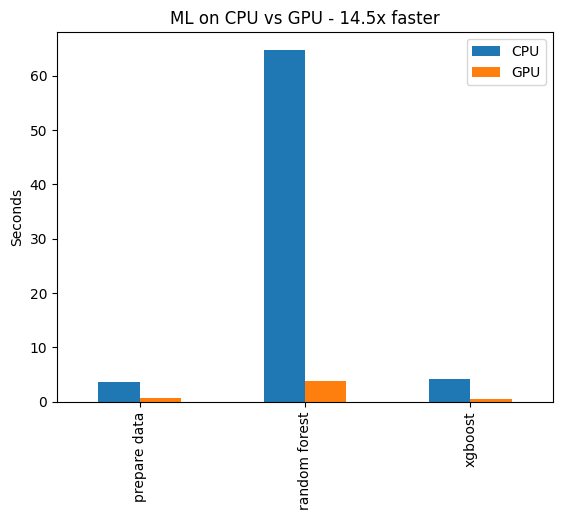

In [ ]:
def run(pd_module, use_gpu):
    import time, numpy as np
    from sklearn.ensemble import RandomForestRegressor
    import xgboost as xgb
    t = {}
    s = time.time()
    df = pd_module.read_parquet("nyc_taxi_data/yellow_tripdata_2024-01.parquet")
    df = df[(df.fare_amount > 0) & (df.fare_amount < 500) & (df.trip_distance > 0) &
            (df.trip_distance < 100) & (df.tip_amount >= 0) & (df.tip_amount < 100) &
            (df.payment_type == 1)]
    df = df.sample(1_000_000, random_state=42)
    df["hour"] = df.tpep_pickup_datetime.dt.hour
    df["dow"] = df.tpep_pickup_datetime.dt.dayofweek
    feats = ["trip_distance", "fare_amount", "passenger_count", "hour", "dow"]
    X = df[feats].fillna(0).astype("float32"); y = df.tip_amount.astype("float32")
    t["prepare data"] = time.time() - s

    s = time.time()
    RandomForestRegressor(n_estimators=100, max_depth=10, max_features="sqrt",
                          n_jobs=-1, random_state=42).fit(X, y)
    t["random forest"] = time.time() - s

    s = time.time()
    params = dict(max_depth=5, n_estimators=100, random_state=42)
    if use_gpu:
        params.update(device="cuda", tree_method="hist")
    xgb.XGBRegressor(**params).fit(X, y)
    t["xgboost"] = time.time() - s
    return t

print("Running on CPU... (slow - wait 2-5 minutes)")
import pandas as pd
cpu = run(pd, False)
print("CPU:", cpu)

import IPython.core.magic
if not hasattr(IPython.core.magic, "output_can_be_silenced"):
    IPython.core.magic.output_can_be_silenced = lambda x: x
%load_ext cudf.pandas
%load_ext cuml.accel
import pandas as gpd
print("Running on GPU...")
gpu = run(gpd, True)
print("GPU:", gpu)

import matplotlib.pyplot as plt
res = pd.DataFrame([cpu, gpu], index=["CPU", "GPU"]).T
speed = res["CPU"].sum() / res["GPU"].sum()
print(res); print(f"\nGPU was {speed:.1f}x faster!")
res.plot(kind="bar", title=f"ML on CPU vs GPU - {speed:.1f}x faster")
plt.ylabel("Seconds"); plt.show()